# Ridge Regression Outlier Analysis

This notebook analyzes outliers in the existing Ridge regression prediction outputs.

It does **not** retrain models and does **not** overwrite existing output files. It reads:

```text
outputs/ridge_test_predictions.csv
```

The goal is to understand how extreme lots affect Ridge metrics and to compute updated metrics under transparent outlier-exclusion scenarios.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

OUTPUT_DIR = Path("outputs")
PREDICTION_FILE = OUTPUT_DIR / "ridge_test_predictions.csv"

ACTUAL_COL = "target_price_usd"
QUARTER_COL = "source_quarter"

MODEL_SPECS = {
    "Ridge - No Estimates": "ridge_pred_no_estimates_usd",
    "Ridge - With Log Estimates": "ridge_pred_with_estimates_usd",
}

PRICE_BUCKETS = [0, 1_000, 5_000, 25_000, 100_000, 500_000, np.inf]
PRICE_BUCKET_LABELS = ["<$1k", "$1k-$5k", "$5k-$25k", "$25k-$100k", "$100k-$500k", "$500k+"]

# Adjustable outlier definitions.
MODEL_ABS_ERROR_OUTLIER_QS = [0.95, 0.99]
TARGET_PRICE_OUTLIER_QS = [0.95, 0.99]
ESTIMATE_RATIO_MIN = 0.25
ESTIMATE_RATIO_MAX = 4.00

## 1. Load Predictions

In [2]:
predictions = pd.read_csv(PREDICTION_FILE)
predictions["sale_date"] = pd.to_datetime(predictions["sale_date"], errors="coerce")

required_cols = [ACTUAL_COL, QUARTER_COL, *MODEL_SPECS.values()]
missing = [col for col in required_cols if col not in predictions.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("prediction rows:", len(predictions))
print("quarters:")
print(predictions[QUARTER_COL].value_counts().sort_index())
predictions.head()

prediction rows: 4000
quarters:
source_quarter
2025Q1    1000
2025Q2    1000
2025Q3    1000
2025Q4    1000
Name: count, dtype: int64


,ID,lot_url,source_quarter,sale_date,target_price_usd,auction_low_estimate_usd,auction_high_estimate_usd,auction_estimate_midpoint_usd,auction_estimate_range_usd,log_auction_low_estimate_usd,log_auction_high_estimate_usd,log_auction_estimate_midpoint_usd,auction_estimate_range_ratio,ridge_pred_no_estimates_usd,ridge_error_no_estimates_usd,ridge_pred_with_estimates_usd,ridge_error_with_estimates_usd
0,76db1fe5-0fc1-45d5-b93c-7bed3a76174b,https://www.bonhams.com/auction/30797/lot/75/c...,2025Q1,2025-02-19,"1,066.670000","1,200.000000","1,800.000000","1,500.000000",600.000000,7.090910,7.496097,7.313887,0.400000,"1,310.828161",244.158161,"1,480.759570",414.089570
1,31c7ebc1-b358-43cd-9523-0590215342ce,https://www.christies.com/en/lot/lot-6519747?l...,2025Q1,2025-01-23,"7,350.000000","5,000.000000","7,000.000000","6,000.000000","2,000.000000",8.517393,8.853808,8.699681,0.333333,"8,736.612858","1,386.612858","6,007.705625","-1,342.294375"
2,a95e5ffe-129d-48dd-8103-5471314c9127,https://www.bonhams.com/auction/30481/lot/180/...,2025Q1,2025-01-16,"2,346.670000","2,000.000000","3,000.000000","2,500.000000","1,000.000000",7.601402,8.006701,7.824446,0.400000,476.842682,"-1,869.827318","2,503.023867",156.353867
3,2feab826-dc65-4829-808c-762b2d4ce41a,https://www.bonhams.com/auction/30987/lot/51/e...,2025Q1,2025-03-19,"10,125.400000","1,518.810000","2,278.210000","1,898.510000",759.400000,7.326341,7.731584,7.549351,0.399998,"2,015.207475","-8,110.192525","2,052.116394","-8,073.283606"
4,9322e8e8-1921-4abe-9926-021ec320eb75,https://www.bonhams.com/auction/30737/lot/9/jo...,2025Q1,2025-02-28,"3,420.480000","1,603.350000","1,924.020000","1,763.685000",320.670000,7.380474,7.562692,7.475727,0.181818,"1,115.198958","-2,305.281042","2,267.324960","-1,153.155040"


## 2. Metric Helpers

In [3]:
def evaluate_predictions(actual, predicted, *, label, extra=None):
    actual = pd.Series(actual, dtype=float)
    predicted = pd.Series(predicted, index=actual.index, dtype=float)
    mask = actual.gt(0) & predicted.notna() & np.isfinite(predicted)
    actual = actual[mask]
    predicted = predicted[mask]

    if len(actual) == 0:
        row = {"model": label, "n": 0, "MAE": np.nan, "RMSE": np.nan, "MAPE": np.nan, "R2": np.nan}
    else:
        residual = predicted - actual
        ss_res = float(np.square(residual).sum())
        ss_tot = float(np.square(actual - actual.mean()).sum())
        row = {
            "model": label,
            "n": int(len(actual)),
            "MAE": float(residual.abs().mean()),
            "RMSE": float(np.sqrt(np.square(residual).mean())),
            "MAPE": float((residual.abs() / actual).mean()),
            "R2": float(1 - ss_res / ss_tot) if ss_tot > 0 and len(actual) > 1 else np.nan,
        }
    if extra:
        row.update(extra)
    return row


def make_long_predictions(frame):
    rows = []
    base_cols = [
        "ID",
        "lot_url",
        QUARTER_COL,
        "sale_date",
        ACTUAL_COL,
        "auction_low_estimate_usd",
        "auction_high_estimate_usd",
        "auction_estimate_midpoint_usd",
        "auction_estimate_range_usd",
        "log_auction_estimate_midpoint_usd",
        "auction_estimate_range_ratio",
    ]
    base_cols = [col for col in base_cols if col in frame.columns]

    for model_name, pred_col in MODEL_SPECS.items():
        part = frame[base_cols].copy()
        part["model"] = model_name
        part["predicted_price_usd"] = pd.to_numeric(frame[pred_col], errors="coerce")
        rows.append(part)

    long = pd.concat(rows, ignore_index=True)
    long[ACTUAL_COL] = pd.to_numeric(long[ACTUAL_COL], errors="coerce")
    long["error_usd"] = long["predicted_price_usd"] - long[ACTUAL_COL]
    long["abs_error_usd"] = long["error_usd"].abs()
    long["squared_error"] = np.square(long["error_usd"])
    long["abs_pct_error"] = long["abs_error_usd"] / long[ACTUAL_COL]
    long["signed_pct_error"] = long["error_usd"] / long[ACTUAL_COL]
    long["price_bucket"] = pd.cut(
        long[ACTUAL_COL],
        bins=PRICE_BUCKETS,
        labels=PRICE_BUCKET_LABELS,
        include_lowest=True,
    )
    return long


long_predictions = make_long_predictions(predictions)
long_predictions.head()

,ID,lot_url,source_quarter,sale_date,target_price_usd,auction_low_estimate_usd,auction_high_estimate_usd,auction_estimate_midpoint_usd,auction_estimate_range_usd,log_auction_estimate_midpoint_usd,auction_estimate_range_ratio,model,predicted_price_usd,error_usd,abs_error_usd,squared_error,abs_pct_error,signed_pct_error,price_bucket
0,76db1fe5-0fc1-45d5-b93c-7bed3a76174b,https://www.bonhams.com/auction/30797/lot/75/c...,2025Q1,2025-02-19,"1,066.670000","1,200.000000","1,800.000000","1,500.000000",600.000000,7.313887,0.400000,Ridge - No Estimates,"1,310.828161",244.158161,244.158161,"59,613.207480",0.228898,0.228898,$1k-$5k
1,31c7ebc1-b358-43cd-9523-0590215342ce,https://www.christies.com/en/lot/lot-6519747?l...,2025Q1,2025-01-23,"7,350.000000","5,000.000000","7,000.000000","6,000.000000","2,000.000000",8.699681,0.333333,Ridge - No Estimates,"8,736.612858","1,386.612858","1,386.612858","1,922,695.219215",0.188655,0.188655,$5k-$25k
2,a95e5ffe-129d-48dd-8103-5471314c9127,https://www.bonhams.com/auction/30481/lot/180/...,2025Q1,2025-01-16,"2,346.670000","2,000.000000","3,000.000000","2,500.000000","1,000.000000",7.824446,0.400000,Ridge - No Estimates,476.842682,"-1,869.827318","1,869.827318","3,496,254.200029",0.796800,-0.796800,$1k-$5k
3,2feab826-dc65-4829-808c-762b2d4ce41a,https://www.bonhams.com/auction/30987/lot/51/e...,2025Q1,2025-03-19,"10,125.400000","1,518.810000","2,278.210000","1,898.510000",759.400000,7.549351,0.399998,Ridge - No Estimates,"2,015.207475","-8,110.192525","8,110.192525","65,775,222.796061",0.800975,-0.800975,$5k-$25k
4,9322e8e8-1921-4abe-9926-021ec320eb75,https://www.bonhams.com/auction/30737/lot/9/jo...,2025Q1,2025-02-28,"3,420.480000","1,603.350000","1,924.020000","1,763.685000",320.670000,7.475727,0.181818,Ridge - No Estimates,"1,115.198958","-2,305.281042","2,305.281042","5,314,320.683458",0.673964,-0.673964,$1k-$5k


## 3. Baseline Metrics

In [4]:
baseline_metrics = pd.DataFrame([
    evaluate_predictions(predictions[ACTUAL_COL], predictions[pred_col], label=model_name)
    for model_name, pred_col in MODEL_SPECS.items()
])
baseline_metrics

,model,n,MAE,RMSE,MAPE,R2
0,Ridge - No Estimates,4000,"116,385.254497","767,508.275594",3.067082,-0.172310
1,Ridge - With Log Estimates,4000,"38,654.834341","225,154.969957",0.762924,0.899112


## 4. Error Distribution Summary

These are not replacement headline metrics. They help diagnose whether RMSE and R2 are being dominated by a small number of lots.

In [5]:
error_summary = (
    long_predictions
    .groupby("model")
    .agg(
        n=("abs_error_usd", "size"),
        mean_error=("error_usd", "mean"),
        median_error=("error_usd", "median"),
        overprediction_rate=("error_usd", lambda s: float((s > 0).mean())),
        abs_error_p50=("abs_error_usd", lambda s: s.quantile(0.50)),
        abs_error_p75=("abs_error_usd", lambda s: s.quantile(0.75)),
        abs_error_p90=("abs_error_usd", lambda s: s.quantile(0.90)),
        abs_error_p95=("abs_error_usd", lambda s: s.quantile(0.95)),
        abs_error_p99=("abs_error_usd", lambda s: s.quantile(0.99)),
        max_abs_error=("abs_error_usd", "max"),
    )
    .reset_index()
)
error_summary

,model,n,mean_error,median_error,overprediction_rate,abs_error_p50,abs_error_p75,abs_error_p90,abs_error_p95,abs_error_p99,max_abs_error
0,Ridge - No Estimates,4000,"-85,205.133403",-390.702874,0.466250,"6,963.554655","27,541.938780","105,878.513040","295,790.051047","2,405,435.128728","20,779,514.607366"
1,Ridge - With Log Estimates,4000,"9,164.952386",417.656505,0.596500,"2,594.791463","11,138.447385","44,213.385789","124,850.706602","789,851.220191","6,392,247.361819"


## 5. Define Outlier Flags

The notebook creates several transparent outlier flags:

- **Model-specific top absolute-error outliers:** top 5% or top 1% by absolute error within each model.
- **Dataset-level high-price lots:** top 5% or top 1% by actual sale price, shared across models.
- **Estimate-ratio anomalies:** auction midpoint is far below or above actual price.

Model-specific trimming is useful for robustness diagnostics, but shared-row exclusions are fairer when comparing models.

In [6]:
work = long_predictions.copy()

for q in MODEL_ABS_ERROR_OUTLIER_QS:
    threshold_col = f"model_abs_error_p{int(q * 100)}_threshold"
    flag_col = f"is_model_top_{int((1 - q) * 100)}pct_abs_error"
    work[threshold_col] = work.groupby("model")["abs_error_usd"].transform(lambda s: s.quantile(q))
    work[flag_col] = work["abs_error_usd"].ge(work[threshold_col])

for q in TARGET_PRICE_OUTLIER_QS:
    threshold = predictions[ACTUAL_COL].quantile(q)
    flag_col = f"is_target_top_{int((1 - q) * 100)}pct_price"
    work[flag_col] = work[ACTUAL_COL].ge(threshold)

if "auction_estimate_midpoint_usd" in work.columns:
    work["estimate_to_actual_ratio"] = work["auction_estimate_midpoint_usd"] / work[ACTUAL_COL]
    work["is_missing_or_nonpositive_estimate"] = work["auction_estimate_midpoint_usd"].isna() | work["auction_estimate_midpoint_usd"].le(0)
    work["is_estimate_ratio_anomaly"] = (
        work["estimate_to_actual_ratio"].lt(ESTIMATE_RATIO_MIN)
        | work["estimate_to_actual_ratio"].gt(ESTIMATE_RATIO_MAX)
        | work["is_missing_or_nonpositive_estimate"]
    )
else:
    work["estimate_to_actual_ratio"] = np.nan
    work["is_missing_or_nonpositive_estimate"] = False
    work["is_estimate_ratio_anomaly"] = False

outlier_counts = []
for model_name, group in work.groupby("model"):
    row = {"model": model_name, "n": len(group)}
    for col in [c for c in work.columns if c.startswith("is_")]:
        row[col] = int(group[col].sum())
        row[f"{col}_pct"] = float(group[col].mean() * 100)
    outlier_counts.append(row)

outlier_counts = pd.DataFrame(outlier_counts)
outlier_counts

,model,n,is_model_top_5pct_abs_error,is_model_top_5pct_abs_error_pct,is_model_top_1pct_abs_error,is_model_top_1pct_abs_error_pct,is_target_top_5pct_price,is_target_top_5pct_price_pct,is_target_top_1pct_price,is_target_top_1pct_price_pct,is_missing_or_nonpositive_estimate,is_missing_or_nonpositive_estimate_pct,is_estimate_ratio_anomaly,is_estimate_ratio_anomaly_pct
0,Ridge - No Estimates,4000,200,5.000000,40,1.000000,200,5.000000,41,1.025000,0,0.000000,225,5.625000
1,Ridge - With Log Estimates,4000,200,5.000000,40,1.000000,200,5.000000,41,1.025000,0,0.000000,225,5.625000


## 6. Updated Metrics Under Outlier Scenarios

These tables are diagnostic. Do not replace the official metrics unless the exclusion rule is explicitly documented.

In [7]:
SCENARIOS = {
    "All rows": lambda df: pd.Series(True, index=df.index),
    "Exclude model top 1% absolute-error rows": lambda df: ~df["is_model_top_1pct_abs_error"],
    "Exclude model top 5% absolute-error rows": lambda df: ~df["is_model_top_5pct_abs_error"],
    "Exclude shared top 1% target-price rows": lambda df: ~df["is_target_top_1pct_price"],
    "Exclude shared top 5% target-price rows": lambda df: ~df["is_target_top_5pct_price"],
    "Exclude estimate-ratio anomalies": lambda df: ~df["is_estimate_ratio_anomaly"],
    "Exclude shared top 1% target + estimate anomalies": lambda df: ~(df["is_target_top_1pct_price"] | df["is_estimate_ratio_anomaly"]),
}

scenario_rows = []
for scenario_name, keep_func in SCENARIOS.items():
    keep_mask = keep_func(work)
    for model_name, group in work[keep_mask].groupby("model"):
        original_n = int((work["model"] == model_name).sum())
        row = evaluate_predictions(
            group[ACTUAL_COL],
            group["predicted_price_usd"],
            label=model_name,
            extra={
                "scenario": scenario_name,
                "n_original": original_n,
                "n_removed": original_n - len(group),
                "removed_pct": (original_n - len(group)) / original_n * 100,
            },
        )
        scenario_rows.append(row)

scenario_metrics = pd.DataFrame(scenario_rows)
scenario_metrics = scenario_metrics[["scenario", "model", "n", "n_original", "n_removed", "removed_pct", "MAE", "RMSE", "MAPE", "R2"]]
scenario_metrics.sort_values(["scenario", "model"])

,scenario,model,n,n_original,n_removed,removed_pct,MAE,RMSE,MAPE,R2
0,All rows,Ridge - No Estimates,4000,4000,0,0.000000,"116,385.254497","767,508.275594",3.067082,-0.172310
1,All rows,Ridge - With Log Estimates,4000,4000,0,0.000000,"38,654.834341","225,154.969957",0.762924,0.899112
10,Exclude estimate-ratio anomalies,Ridge - No Estimates,3775,4000,225,5.625000,"120,886.490467","789,406.075645",2.385400,-0.172560
11,Exclude estimate-ratio anomalies,Ridge - With Log Estimates,3775,4000,225,5.625000,"38,925.744748","230,826.403164",0.489096,0.899745
2,Exclude model top 1% absolute-error rows,Ridge - No Estimates,3960,4000,40,1.000000,"57,728.778764","217,644.971883",3.053345,0.221636
3,Exclude model top 1% absolute-error rows,Ridge - With Log Estimates,3960,4000,40,1.000000,"21,665.479304","74,104.683856",0.765457,0.976400
4,Exclude model top 5% absolute-error rows,Ridge - No Estimates,3800,4000,200,5.000000,"22,570.345569","48,516.562790",2.940160,0.447122
5,Exclude model top 5% absolute-error rows,Ridge - With Log Estimates,3800,4000,200,5.000000,"9,392.779368","20,542.159036",0.734627,0.996749
12,Exclude shared top 1% target + estimate anomalies,Ridge - No Estimates,3734,4000,266,6.650000,"63,884.588522","394,197.586847",2.401252,-1.811693
13,Exclude shared top 1% target + estimate anomalies,Ridge - With Log Estimates,3734,4000,266,6.650000,"23,591.149528","99,954.032271",0.491265,0.819224


## 7. Quarterly Metrics Under Selected Scenarios

In [8]:
SELECTED_QUARTER_SCENARIOS = {
    "All rows": SCENARIOS["All rows"],
    "Exclude model top 1% absolute-error rows": SCENARIOS["Exclude model top 1% absolute-error rows"],
    "Exclude shared top 1% target-price rows": SCENARIOS["Exclude shared top 1% target-price rows"],
}

quarter_rows = []
for scenario_name, keep_func in SELECTED_QUARTER_SCENARIOS.items():
    keep_mask = keep_func(work)
    kept = work[keep_mask]
    for (quarter, model_name), group in kept.groupby([QUARTER_COL, "model"]):
        original_n = int(((work[QUARTER_COL] == quarter) & (work["model"] == model_name)).sum())
        row = evaluate_predictions(
            group[ACTUAL_COL],
            group["predicted_price_usd"],
            label=model_name,
            extra={
                "scenario": scenario_name,
                "quarter": quarter,
                "n_original": original_n,
                "n_removed": original_n - len(group),
            },
        )
        quarter_rows.append(row)

quarter_scenario_metrics = pd.DataFrame(quarter_rows)
quarter_scenario_metrics = quarter_scenario_metrics[["scenario", "quarter", "model", "n", "n_original", "n_removed", "MAE", "RMSE", "MAPE", "R2"]]
quarter_scenario_metrics.sort_values(["scenario", "quarter", "model"])

,scenario,quarter,model,n,n_original,n_removed,MAE,RMSE,MAPE,R2
0,All rows,2025Q1,Ridge - No Estimates,1000,1000,0,"66,497.752206","379,223.609526",2.579188,0.152989
1,All rows,2025Q1,Ridge - With Log Estimates,1000,1000,0,"28,944.342731","180,549.553144",0.779289,0.808004
2,All rows,2025Q2,Ridge - No Estimates,1000,1000,0,"195,835.365147","1,168,087.786508",2.124852,-0.372962
3,All rows,2025Q2,Ridge - With Log Estimates,1000,1000,0,"48,357.572981","203,252.506952",0.839344,0.958430
4,All rows,2025Q3,Ridge - No Estimates,1000,1000,0,"38,690.533265","230,953.881757",5.006013,-0.643464
5,All rows,2025Q3,Ridge - With Log Estimates,1000,1000,0,"13,465.741131","61,282.502856",0.834175,0.884287
6,All rows,2025Q4,Ridge - No Estimates,1000,1000,0,"164,517.367368","891,457.510995",2.558273,0.002506
7,All rows,2025Q4,Ridge - With Log Estimates,1000,1000,0,"63,851.680522","353,714.254881",0.598889,0.842959
8,Exclude model top 1% absolute-error rows,2025Q1,Ridge - No Estimates,997,1000,3,"49,441.269961","198,925.367598",2.584121,0.339520
9,Exclude model top 1% absolute-error rows,2025Q1,Ridge - With Log Estimates,993,1000,7,"17,190.280883","55,897.500507",0.780631,0.945651


## 8. Price-Bucket Metrics Under Selected Scenarios

In [9]:
SELECTED_BUCKET_SCENARIOS = {
    "All rows": SCENARIOS["All rows"],
    "Exclude model top 1% absolute-error rows": SCENARIOS["Exclude model top 1% absolute-error rows"],
    "Exclude shared top 1% target-price rows": SCENARIOS["Exclude shared top 1% target-price rows"],
}

bucket_rows = []
for scenario_name, keep_func in SELECTED_BUCKET_SCENARIOS.items():
    keep_mask = keep_func(work)
    kept = work[keep_mask]
    for (bucket, model_name), group in kept.groupby(["price_bucket", "model"], observed=False):
        if group.empty:
            continue
        original_n = int(((work["price_bucket"] == bucket) & (work["model"] == model_name)).sum())
        row = evaluate_predictions(
            group[ACTUAL_COL],
            group["predicted_price_usd"],
            label=model_name,
            extra={
                "scenario": scenario_name,
                "price_bucket": str(bucket),
                "n_original": original_n,
                "n_removed": original_n - len(group),
            },
        )
        bucket_rows.append(row)

bucket_scenario_metrics = pd.DataFrame(bucket_rows)
bucket_scenario_metrics = bucket_scenario_metrics[["scenario", "price_bucket", "model", "n", "n_original", "n_removed", "MAE", "RMSE", "MAPE", "R2"]]
bucket_scenario_metrics.sort_values(["scenario", "price_bucket", "model"])

,scenario,price_bucket,model,n,n_original,n_removed,MAE,RMSE,MAPE,R2
8,All rows,$100k-$500k,Ridge - No Estimates,302,302,0,"230,632.272015","1,145,140.793114",0.910023,-116.048957
9,All rows,$100k-$500k,Ridge - With Log Estimates,302,302,0,"80,758.694686","107,120.658132",0.382613,-0.024227
2,All rows,$1k-$5k,Ridge - No Estimates,1256,1256,0,"8,098.542435","42,541.792710",3.713324,"-1,446.578290"
3,All rows,$1k-$5k,Ridge - With Log Estimates,1256,1256,0,"2,034.229392","8,466.597339",0.841233,-56.336120
6,All rows,$25k-$100k,Ridge - No Estimates,633,633,0,"46,317.519541","203,539.186492",0.979467,-101.515020
7,All rows,$25k-$100k,Ridge - With Log Estimates,633,633,0,"18,779.908342","25,361.966151",0.391709,-0.591686
10,All rows,$500k+,Ridge - No Estimates,163,163,0,"2,071,106.169706","3,441,755.121771",0.852813,-0.603727
11,All rows,$500k+,Ridge - With Log Estimates,163,163,0,"661,483.975553","1,103,680.157832",0.329832,0.835086
4,All rows,$5k-$25k,Ridge - No Estimates,1252,1252,0,"13,271.563493","24,457.620387",1.234990,-19.881385
5,All rows,$5k-$25k,Ridge - With Log Estimates,1252,1252,0,"6,066.425139","14,489.804870",0.543898,-6.329190


## 9. Top Outlier Rows

In [10]:
TOP_N = 25

top_outliers = (
    work
    .sort_values(["model", "abs_error_usd"], ascending=[True, False])
    .groupby("model")
    .head(TOP_N)
    [[
        "model",
        QUARTER_COL,
        "sale_date",
        ACTUAL_COL,
        "predicted_price_usd",
        "error_usd",
        "abs_error_usd",
        "abs_pct_error",
        "auction_estimate_midpoint_usd",
        "estimate_to_actual_ratio",
        "lot_url",
    ]]
)
top_outliers

,model,source_quarter,sale_date,target_price_usd,predicted_price_usd,error_usd,abs_error_usd,abs_pct_error,auction_estimate_midpoint_usd,estimate_to_actual_ratio,lot_url
1518,Ridge - No Estimates,2025Q2,2025-05-14,"20,827,272.730000","47,758.122634","-20,779,514.607366","20,779,514.607366",0.997707,"25,000,000.000000",1.200349,https://www.christies.com/en/lot/lot-6534763?l...
1833,Ridge - No Estimates,2025Q2,2025-06-26,"385,397.850000","19,975,066.832202","19,589,668.982202","19,589,668.982202",50.829731,"506,269.760000",1.313629,https://www.christies.com/en/lot/lot-6543308?l...
3871,Ridge - No Estimates,2025Q4,2025-10-15,"15,843,942.250000","145,102.973562","-15,698,839.276438","15,698,839.276438",0.990842,"8,859,720.790000",0.559187,https://www.christies.com/en/lot/lot-6553043?l...
3699,Ridge - No Estimates,2025Q4,2025-10-16,"14,509,231.060000","67,611.160184","-14,441,619.899816","14,441,619.899816",0.995340,"9,492,557.990000",0.654243,https://www.sothebys.com/en/buy/auction/2025/c...
3646,Ridge - No Estimates,2025Q4,2025-10-24,"9,865,461.130000","24,387.766295","-9,841,073.363705","9,841,073.363705",0.997528,"6,413,400.000000",0.650086,https://www.sothebys.com/en/buy/auction/2025/s...
1931,Ridge - No Estimates,2025Q2,2025-05-21,"9,090,909.090000","40,712.941884","-9,050,196.148116","9,050,196.148116",0.995522,"12,500,000.000000",1.375000,https://www.sothebys.com/en/buy/auction/2025/e...
1360,Ridge - No Estimates,2025Q2,2025-05-12,"8,281,818.180000","79,982.794820","-8,201,835.385180","8,201,835.385180",0.990342,"10,000,000.000000",1.207464,https://www.christies.com/en/lot/lot-6534216?l...
275,Ridge - No Estimates,2025Q1,2025-03-05,"7,059,011.310000","77,890.918148","-6,981,120.391852","6,981,120.391852",0.988966,"8,226,883.590000",1.165444,https://www.christies.com/en/lot/lot-6523684?l...
1604,Ridge - No Estimates,2025Q2,2025-05-15,"6,818,181.820000","82,593.009156","-6,735,588.810844","6,735,588.810844",0.987886,"10,000,000.000000",1.466667,https://www.sothebys.com/en/buy/auction/2025/c...
919,Ridge - No Estimates,2025Q1,2025-03-05,"6,529,729.290000","121,730.245753","-6,407,999.044247","6,407,999.044247",0.981358,"1,898,511.600000",0.290749,https://www.christies.com/en/lot/lot-6523639?l...


## 10. Error Concentration

This estimates how much of total squared error comes from the worst few rows. A high concentration means RMSE/R2 are dominated by outliers.

In [11]:
concentration_rows = []
for model_name, group in work.groupby("model"):
    sorted_group = group.sort_values("squared_error", ascending=False).copy()
    total_sse = sorted_group["squared_error"].sum()
    for top_n in [1, 5, 10, 25, 50, 100]:
        top_sse = sorted_group.head(top_n)["squared_error"].sum()
        concentration_rows.append({
            "model": model_name,
            "top_n_rows": top_n,
            "total_rows": len(sorted_group),
            "squared_error_share": top_sse / total_sse if total_sse > 0 else np.nan,
        })

error_concentration = pd.DataFrame(concentration_rows)
error_concentration

,model,top_n_rows,total_rows,squared_error_share
0,Ridge - No Estimates,1,4000,0.183250
1,Ridge - No Estimates,5,4000,0.580324
2,Ridge - No Estimates,10,4000,0.700999
3,Ridge - No Estimates,25,4000,0.862713
4,Ridge - No Estimates,50,4000,0.942216
5,Ridge - No Estimates,100,4000,0.982969
6,Ridge - With Log Estimates,1,4000,0.201504
7,Ridge - With Log Estimates,5,4000,0.532864
8,Ridge - With Log Estimates,10,4000,0.687703
9,Ridge - With Log Estimates,25,4000,0.837032


## 11. Optional Visual Diagnostics

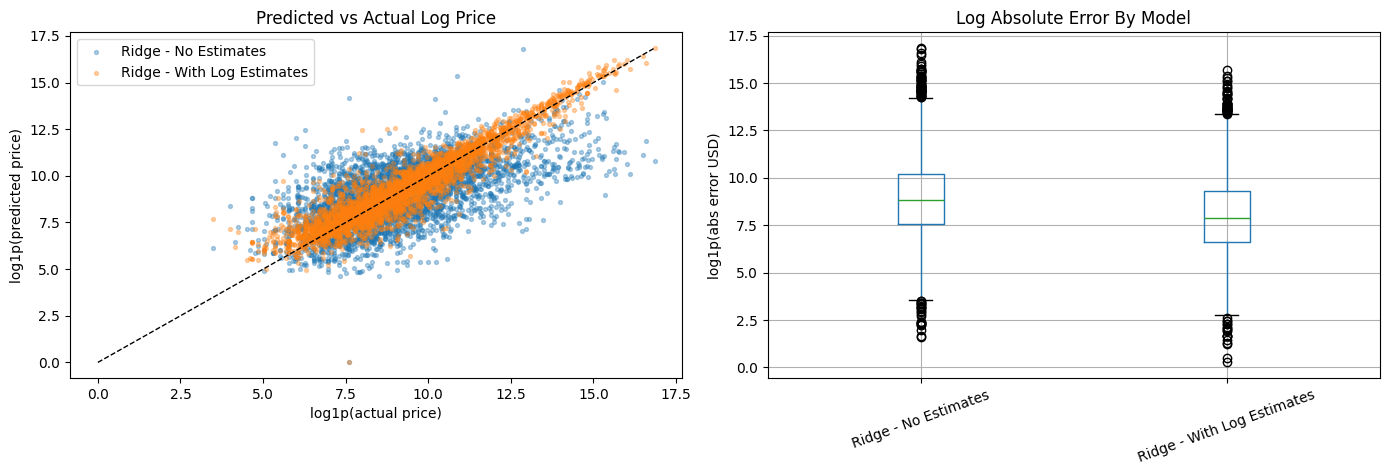

In [12]:
import matplotlib.pyplot as plt

plot_frame = work.copy()
plot_frame["log_actual"] = np.log1p(plot_frame[ACTUAL_COL])
plot_frame["log_predicted"] = np.log1p(plot_frame["predicted_price_usd"].clip(lower=0))
plot_frame["log_abs_error"] = np.log1p(plot_frame["abs_error_usd"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, group in plot_frame.groupby("model"):
    axes[0].scatter(group["log_actual"], group["log_predicted"], s=8, alpha=0.35, label=model_name)
axes[0].plot([0, plot_frame["log_actual"].max()], [0, plot_frame["log_actual"].max()], linestyle="--", color="black", linewidth=1)
axes[0].set_title("Predicted vs Actual Log Price")
axes[0].set_xlabel("log1p(actual price)")
axes[0].set_ylabel("log1p(predicted price)")
axes[0].legend()

plot_frame.boxplot(column="log_abs_error", by="model", ax=axes[1], rot=20)
axes[1].set_title("Log Absolute Error By Model")
axes[1].set_xlabel("")
axes[1].set_ylabel("log1p(abs error USD)")
fig.suptitle("")
plt.tight_layout()
plt.show()

## 12. Interpretation Notes

Suggested reporting language:

- Use the all-row metrics as the official model performance.
- Use outlier-excluded metrics as sensitivity checks, not as replacements.
- If the ranking changes only after excluding model-specific outliers, state that the result is sensitive to extreme lots.
- Shared exclusions, such as top 1% actual price, are fairer for comparing models because they remove the same lots for both models.
- If RMSE/R2 change sharply after removing a very small number of rows, the model is highly outlier-sensitive.